In [352]:
import pandas as pd
import requests
import statsmodels as sm
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as plt
import seaborn as sns
import csv
import time
from scipy import io
import scipy.stats
import statsmodels.api as sm
import importlib




In [353]:
DataFrame_incidenti = pd.read_csv('DataFrame_incidenti', na_values=['', 'NaN', 'null'], keep_default_na=False)
DataFrame_incidenti.isna().sum()

Unnamed: 0                 0
NOME_COMUNE                0
TIPO_COMUNE                0
CODICE_AREA                0
CODICE_REGIONE             0
ANNO                       0
SUPERFICIE_KMQ             0
POPOLAZIONE                0
RIPARTIZIONE_GEOGRAFICA    0
TIPO_INCIDENTE             0
RISULTATO_INCIDENTE        0
NUMERO_INCIDENTI           0
ZONA_ALTIMETRICA           0
ALTITUDINE_m               0
PRESENZA_MONTAGNE          0
COMUNE_LITORANEO           0
dtype: int64

# Raggruppo i dati per comune, anno e categoria per evitare doppioni, sommo il totale degli incidenti e prendo il valore massimo per la popolazione e la superficie territoriale.


In [354]:
df_intermedio = DataFrame_incidenti.groupby(
    ['NOME_COMUNE', 'ANNO', 'CODICE_REGIONE', 'TIPO_COMUNE', 'RIPARTIZIONE_GEOGRAFICA', 'ZONA_ALTIMETRICA', 'ALTITUDINE_m', 'RISULTATO_INCIDENTE', 'PRESENZA_MONTAGNE', 'COMUNE_LITORANEO']
).agg({
    'NUMERO_INCIDENTI': 'sum',
    'POPOLAZIONE': 'max',
    'SUPERFICIE_KMQ': 'max'
}).reset_index()
df_intermedio

,NOME_COMUNE,ANNO,CODICE_REGIONE,TIPO_COMUNE,RIPARTIZIONE_GEOGRAFICA,ZONA_ALTIMETRICA,ALTITUDINE_m,RISULTATO_INCIDENTE,PRESENZA_MONTAGNE,COMUNE_LITORANEO,NUMERO_INCIDENTI,POPOLAZIONE,SUPERFICIE_KMQ
0,Abano Terme,2010,VENETO,Provincia,Nord-est,pianura,14.0,EVENTI,NON MONTANO,NON LITORANEO,80,19349.0,21.4084
1,Abano Terme,2010,VENETO,Provincia,Nord-est,pianura,14.0,FERITI,NON MONTANO,NON LITORANEO,101,19349.0,21.4084
2,Abano Terme,2010,VENETO,Provincia,Nord-est,pianura,14.0,MORTI,NON MONTANO,NON LITORANEO,0,19349.0,21.4084
3,Abano Terme,2011,VENETO,Provincia,Nord-est,pianura,14.0,EVENTI,NON MONTANO,NON LITORANEO,60,19349.0,21.4084
4,Abano Terme,2011,VENETO,Provincia,Nord-est,pianura,14.0,FERITI,NON MONTANO,NON LITORANEO,74,19349.0,21.4084
...,...,...,...,...,...,...,...,...,...,...,...,...,...
339112,Zungri,2023,CALABRIA,Provincia,Sud,collina interna,554.0,FERITI,NON MONTANO,NON LITORANEO,1,1985.0,23.4553
339113,Zungri,2023,CALABRIA,Provincia,Sud,collina interna,554.0,MORTI,NON MONTANO,NON LITORANEO,0,1985.0,23.4553
339114,Zungri,2024,CALABRIA,Provincia,Sud,collina interna,554.0,EVENTI,NON MONTANO,NON LITORANEO,3,1985.0,23.4553
339115,Zungri,2024,CALABRIA,Provincia,Sud,collina interna,554.0,FERITI,NON MONTANO,NON LITORANEO,5,1985.0,23.4553


Trasformiamo le righe in colonne affiancate (Eventi, Feriti, Morti)


In [355]:
incidenti_agg = df_intermedio.pivot_table(
    index=['NOME_COMUNE', 'ANNO', 'CODICE_REGIONE', 'TIPO_COMUNE', 'RIPARTIZIONE_GEOGRAFICA', 'ZONA_ALTIMETRICA', 'POPOLAZIONE', 'SUPERFICIE_KMQ', 'ALTITUDINE_m', 'PRESENZA_MONTAGNE', 'COMUNE_LITORANEO'],
    columns='RISULTATO_INCIDENTE',
    values='NUMERO_INCIDENTI',
    aggfunc='sum'
).reset_index()

In [356]:
# Calcoliamo gli indicatori chiave sul totale degli eventi
incidenti_agg['ACC_KMQ'] = incidenti_agg['EVENTI'] / incidenti_agg['SUPERFICIE_KMQ']
incidenti_agg['ACC_RATE'] = (incidenti_agg['EVENTI'] / incidenti_agg['POPOLAZIONE']) * 1000

# qui semplicemente elimino il nome della colonna "RISULTATO_INCIDENTE" che si può vedere come prima colonna, è causato dal pivot del dataframe
incidenti_agg.columns.name = None

incidenti_agg

,NOME_COMUNE,ANNO,CODICE_REGIONE,TIPO_COMUNE,RIPARTIZIONE_GEOGRAFICA,ZONA_ALTIMETRICA,POPOLAZIONE,SUPERFICIE_KMQ,ALTITUDINE_m,PRESENZA_MONTAGNE,COMUNE_LITORANEO,EVENTI,FERITI,MORTI,ACC_KMQ,ACC_RATE
0,Abano Terme,2010,VENETO,Provincia,Nord-est,pianura,19349.0,21.4084,14.0,NON MONTANO,NON LITORANEO,80,101,0,3.736851,4.134581
1,Abano Terme,2011,VENETO,Provincia,Nord-est,pianura,19349.0,21.4084,14.0,NON MONTANO,NON LITORANEO,60,74,1,2.802638,3.100935
2,Abano Terme,2012,VENETO,Provincia,Nord-est,pianura,19349.0,21.4084,14.0,NON MONTANO,NON LITORANEO,30,36,0,1.401319,1.550468
3,Abano Terme,2013,VENETO,Provincia,Nord-est,pianura,19349.0,21.4084,14.0,NON MONTANO,NON LITORANEO,64,82,2,2.989481,3.307664
4,Abano Terme,2014,VENETO,Provincia,Nord-est,pianura,19349.0,21.4084,14.0,NON MONTANO,NON LITORANEO,67,80,1,3.129613,3.462711
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113034,Zungri,2020,CALABRIA,Provincia,Sud,collina interna,1985.0,23.4553,554.0,NON MONTANO,NON LITORANEO,1,2,0,0.042634,0.503778
113035,Zungri,2021,CALABRIA,Provincia,Sud,collina interna,1985.0,23.4553,554.0,NON MONTANO,NON LITORANEO,1,1,0,0.042634,0.503778
113036,Zungri,2022,CALABRIA,Provincia,Sud,collina interna,1985.0,23.4553,554.0,NON MONTANO,NON LITORANEO,1,2,0,0.042634,0.503778
113037,Zungri,2023,CALABRIA,Provincia,Sud,collina interna,1985.0,23.4553,554.0,NON MONTANO,NON LITORANEO,1,1,0,0.042634,0.503778


In [357]:
incidenti_agg.describe()

,ANNO,POPOLAZIONE,SUPERFICIE_KMQ,ALTITUDINE_m,EVENTI,FERITI,MORTI,ACC_KMQ,ACC_RATE
count,113039.000000,1.130390e+05,113039.000000,113039.000000,113039.000000,113039.000000,113039.000000,113039.000000,113039.000000
mean,2016.912216,7.728051e+03,37.403697,353.446793,22.844593,31.865250,0.429082,0.674098,1.786194
std,4.270569,4.114105e+04,50.316849,296.151176,214.547612,280.278797,2.199681,1.775179,1.928629
min,2010.000000,3.000000e+01,0.120600,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2013.000000,1.084000e+03,11.308000,113.000000,1.000000,1.000000,0.000000,0.026627,0.469778
50%,2017.000000,2.587000e+03,21.992600,287.000000,3.000000,5.000000,0.000000,0.155831,1.428827
75%,2021.000000,6.506000e+03,43.526900,516.000000,12.000000,18.000000,0.000000,0.562071,2.541802
max,2024.000000,2.617175e+06,1287.358600,2035.000000,18496.000000,24467.000000,186.000000,66.520727,95.238095


In [358]:
colonne = ['NOME_COMUNE','CODICE_REGIONE','TIPO_COMUNE','RIPARTIZIONE_GEOGRAFICA','ZONA_ALTIMETRICA','PRESENZA_MONTAGNE','COMUNE_LITORANEO','SUPERFICIE_KMQ','ALTITUDINE_m']

incidenti_totale = (incidenti_agg.groupby(colonne).agg({'EVENTI': 'sum','FERITI': 'sum','MORTI': 'sum','POPOLAZIONE': 'mean'}).reset_index())

incidenti_totale['ACC_RATE'] = (incidenti_totale['EVENTI'] / incidenti_totale['POPOLAZIONE']) * 1000
incidenti_totale['ACC_KMQ'] = (incidenti_totale['EVENTI'] / incidenti_totale['SUPERFICIE_KMQ'])

incidenti_totale

,NOME_COMUNE,CODICE_REGIONE,TIPO_COMUNE,RIPARTIZIONE_GEOGRAFICA,ZONA_ALTIMETRICA,PRESENZA_MONTAGNE,COMUNE_LITORANEO,SUPERFICIE_KMQ,ALTITUDINE_m,EVENTI,FERITI,MORTI,POPOLAZIONE,ACC_RATE,ACC_KMQ
0,Abano Terme,VENETO,Provincia,Nord-est,pianura,NON MONTANO,NON LITORANEO,21.4084,14.0,817,999,12,19349.0,42.224404,38.162590
1,Abbadia Cerreto,LOMBARDIA,Provincia,Nord-ovest,pianura,NON MONTANO,NON LITORANEO,6.1987,64.0,0,0,0,297.0,0.000000,0.000000
2,Abbadia Lariana,LOMBARDIA,Provincia,Nord-ovest,montagna interna,TOTALMENTE MONTANO,NON LITORANEO,16.6727,204.0,437,623,6,3249.0,134.502924,26.210512
3,Abbadia San Salvatore,TOSCANA,Provincia,Centro,montagna interna,TOTALMENTE MONTANO,NON LITORANEO,58.9942,822.0,130,186,3,6557.0,19.826140,2.203606
4,Abbasanta,SARDEGNA,Provincia,Isole,collina interna,TOTALMENTE MONTANO,NON LITORANEO,39.8475,315.0,60,94,2,2828.0,21.216407,1.505741
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7641,Zuglio,FRIULI_VG,Provincia,Nord-est,montagna interna,TOTALMENTE MONTANO,NON LITORANEO,18.2115,429.0,4,5,0,606.0,6.600660,0.219641
7642,Zumaglia,PIEMONTE,Provincia,Nord-ovest,collina interna,TOTALMENTE MONTANO,NON LITORANEO,2.6137,573.0,10,12,0,1129.0,8.857396,3.825994
7643,Zumpano,CALABRIA,Provincia,Sud,collina interna,NON MONTANO,NON LITORANEO,8.0839,429.0,35,73,1,2468.0,14.181524,4.329593
7644,Zungoli,CAMPANIA,Provincia,Sud,montagna interna,TOTALMENTE MONTANO,NON LITORANEO,19.2181,657.0,0,0,0,1197.0,0.000000,0.000000


In [359]:
incidenti_totale.describe()

,SUPERFICIE_KMQ,ALTITUDINE_m,EVENTI,FERITI,MORTI,POPOLAZIONE,ACC_RATE,ACC_KMQ
count,7646.000000,7646.000000,7646.000000,7646.000000,7646.000000,7.646000e+03,7646.000000,7646.000000
mean,37.254357,355.769683,337.736071,471.098091,6.343578,7.637746e+03,26.407219,9.965910
std,50.086746,296.976492,3145.865951,4096.725973,30.765818,4.085444e+04,21.452168,25.617475
min,0.120600,0.000000,0.000000,0.000000,0.000000,3.000000e+01,0.000000,0.000000
25%,11.265650,115.000000,15.000000,22.000000,0.000000,1.056000e+03,11.801151,0.637961
50%,21.949050,289.000000,53.000000,80.000000,2.000000,2.541000e+03,22.026224,2.419837
75%,43.424175,520.000000,172.000000,260.000000,6.000000,6.412000e+03,35.178964,8.285199
max,1287.358600,2035.000000,203438.000000,263031.000000,2200.000000,2.617175e+06,265.822785,723.471386


In [360]:
incidenti_agg.describe()

,ANNO,POPOLAZIONE,SUPERFICIE_KMQ,ALTITUDINE_m,EVENTI,FERITI,MORTI,ACC_KMQ,ACC_RATE
count,113039.000000,1.130390e+05,113039.000000,113039.000000,113039.000000,113039.000000,113039.000000,113039.000000,113039.000000
mean,2016.912216,7.728051e+03,37.403697,353.446793,22.844593,31.865250,0.429082,0.674098,1.786194
std,4.270569,4.114105e+04,50.316849,296.151176,214.547612,280.278797,2.199681,1.775179,1.928629
min,2010.000000,3.000000e+01,0.120600,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2013.000000,1.084000e+03,11.308000,113.000000,1.000000,1.000000,0.000000,0.026627,0.469778
50%,2017.000000,2.587000e+03,21.992600,287.000000,3.000000,5.000000,0.000000,0.155831,1.428827
75%,2021.000000,6.506000e+03,43.526900,516.000000,12.000000,18.000000,0.000000,0.562071,2.541802
max,2024.000000,2.617175e+06,1287.358600,2035.000000,18496.000000,24467.000000,186.000000,66.520727,95.238095


### Ho deciso di mantenere due versioni finali del dataframe:
#### **incidenti_agg** : ci permette di vedere l'avvenire dei fatti durante gli anni in modo da poter vedere come cambiano nel tempo
#### **incidenti_totale** : con questo possiamo valutare le varie classifiche con il totale dei risultati con 15 anni di dati 

In [361]:
top_acc_rate = incidenti_totale.sort_values(by='ACC_RATE', ascending=False).reset_index(drop=True)
top_acc_rate.head(10)

,NOME_COMUNE,CODICE_REGIONE,TIPO_COMUNE,RIPARTIZIONE_GEOGRAFICA,ZONA_ALTIMETRICA,PRESENZA_MONTAGNE,COMUNE_LITORANEO,SUPERFICIE_KMQ,ALTITUDINE_m,EVENTI,FERITI,MORTI,POPOLAZIONE,ACC_RATE,ACC_KMQ
0,Argentera,PIEMONTE,Provincia,Nord-ovest,montagna interna,TOTALMENTE MONTANO,NON LITORANEO,76.2603,1684.0,21,30,1,79.0,265.822785,0.275373
1,Bard,VALLE D_AOSTA,Provincia,Nord-ovest,montagna interna,TOTALMENTE MONTANO,NON LITORANEO,3.0315,400.0,31,45,3,125.0,248.000000,10.225961
2,Ponte Gardena,TRENTINO_AA.,Provincia,Nord-est,montagna interna,TOTALMENTE MONTANO,NON LITORANEO,2.3282,470.0,44,61,0,195.0,225.641026,18.898720
3,Priero,PIEMONTE,Provincia,Nord-ovest,montagna interna,TOTALMENTE MONTANO,NON LITORANEO,20.0100,475.0,107,182,2,487.0,219.712526,5.347326
4,Moncenisio,PIEMONTE,Provincia,Nord-ovest,montagna interna,TOTALMENTE MONTANO,NON LITORANEO,4.5008,1461.0,9,10,1,42.0,214.285714,1.999645
5,Dorio,LOMBARDIA,Provincia,Nord-ovest,montagna interna,TOTALMENTE MONTANO,NON LITORANEO,11.6557,210.0,72,114,2,337.0,213.649852,6.177235
6,Belforte Monferrato,PIEMONTE,Provincia,Nord-ovest,collina interna,NON MONTANO,NON LITORANEO,8.3260,297.0,107,161,4,505.0,211.881188,12.851309
7,Forte dei Marmi,TOSCANA,Provincia,Centro,pianura,NON MONTANO,LITORANEO,8.8804,2.0,1583,2114,10,7660.0,206.657963,178.257736
8,Rocca Pia,ABRUZZO,Provincia,Sud,montagna interna,TOTALMENTE MONTANO,NON LITORANEO,44.9618,1181.0,32,56,4,167.0,191.616766,0.711715
9,Bergeggi,LIGURIA,Provincia,Nord-ovest,collina litoranea,NON MONTANO,LITORANEO,3.6899,110.0,201,296,2,1126.0,178.507993,54.473021


In [362]:
top_acc_kmq = incidenti_totale.sort_values(by='ACC_KMQ', ascending=False).reset_index(drop=True)
top_acc_kmq.head(10)

,NOME_COMUNE,CODICE_REGIONE,TIPO_COMUNE,RIPARTIZIONE_GEOGRAFICA,ZONA_ALTIMETRICA,PRESENZA_MONTAGNE,COMUNE_LITORANEO,SUPERFICIE_KMQ,ALTITUDINE_m,EVENTI,FERITI,MORTI,POPOLAZIONE,ACC_RATE,ACC_KMQ
0,Milano,LOMBARDIA,Capoluogo di regione,Nord-ovest,pianura,NON MONTANO,NON LITORANEO,181.6727,122.0,131435,170964,676,1242123.0,105.814803,723.471386
1,Cinisello Balsamo,LOMBARDIA,Provincia,Nord-ovest,pianura,NON MONTANO,NON LITORANEO,12.7243,154.0,4749,6318,37,71128.0,66.766955,373.222888
2,Firenze,TOSCANA,Capoluogo di regione,Centro,collina interna,NON MONTANO,NON LITORANEO,102.3187,50.0,37764,45511,216,358079.0,105.462761,369.082093
3,Torino,PIEMONTE,Capoluogo di regione,Nord-ovest,pianura,NON MONTANO,NON LITORANEO,130.0111,239.0,46005,67927,406,872367.0,52.735833,353.854402
4,Corsico,LOMBARDIA,Provincia,Nord-ovest,pianura,NON MONTANO,NON LITORANEO,5.3573,115.0,1882,2464,14,33669.0,55.897116,351.296362
5,Bergamo,LOMBARDIA,Capoluogo di provincia,Nord-ovest,collina interna,NON MONTANO,NON LITORANEO,40.1579,249.0,13483,17371,71,115349.0,116.888746,335.749628
6,Cormano,LOMBARDIA,Provincia,Nord-ovest,pianura,NON MONTANO,NON LITORANEO,4.4734,149.0,1426,1978,11,19944.0,71.500201,318.773193
7,Portici,CAMPANIA,Provincia,Sud,collina litoranea,NON MONTANO,LITORANEO,4.6049,29.0,1341,1712,7,55765.0,24.047342,291.211536
8,Napoli,CAMPANIA,Capoluogo di regione,Sud,collina litoranea,NON MONTANO,LITORANEO,119.0233,17.0,34273,45709,468,962003.0,35.626708,287.952023
9,Monza,LOMBARDIA,Capoluogo di provincia,Nord-ovest,pianura,NON MONTANO,NON LITORANEO,33.0871,162.0,9290,12007,61,119856.0,77.509678,280.774078


## Analizzando la classifica dei tassi di incidenti (`ACC_RATE`) possiamo notare che alcune città hanno numeri insoliti 
## ma ragionevoli:

### 1. Paesi come `Argentera`  hanno pochissimi residenti fissi e bastano pochi incidenti nel giro di 15 anni per aumentare il rateo di incidenti tra i più alti


### 2. Località turistiche o di passaggio, `come Forte dei Marmi` in Toscana, hanno pochi abitanti rispetto ad altre cittò, ma subiscono un afflusso massiccio di turisti e pendolari.

In [363]:
top_acc_rate = incidenti_totale.sort_values(by='ACC_RATE', ascending=False).head(1)
top_acc_kqm = incidenti_totale.sort_values(by='ACC_KMQ', ascending=False).head(1)
top_eventi = incidenti_totale.sort_values(by='EVENTI', ascending=False).head(1)


top_categories = pd.concat([top_acc_rate, top_acc_kqm, top_eventi])
top_categories['CATEGORIA'] = ['RATEO INCIDENTI PIU ALTO','MAGGIORI INCIDENTI PER KMQ','MAGGIOR NUMERO DI EVENTI']
top_categories[['CATEGORIA','NOME_COMUNE','CODICE_REGIONE', 'ALTITUDINE_m', 'ZONA_ALTIMETRICA','POPOLAZIONE','SUPERFICIE_KMQ','EVENTI','ACC_RATE','ACC_KMQ']]


,CATEGORIA,NOME_COMUNE,CODICE_REGIONE,ALTITUDINE_m,ZONA_ALTIMETRICA,POPOLAZIONE,SUPERFICIE_KMQ,EVENTI,ACC_RATE,ACC_KMQ
307,RATEO INCIDENTI PIU ALTO,Argentera,PIEMONTE,1684.0,montagna interna,79.0,76.2603,21,265.822785,0.275373
3866,MAGGIORI INCIDENTI PER KMQ,Milano,LOMBARDIA,122.0,pianura,1242123.0,181.6727,131435,105.814803,723.471386
5613,MAGGIOR NUMERO DI EVENTI,Roma,LAZIO,20.0,pianura,2617175.0,1287.3586,203438,77.731906,158.027452


**Qui ho provato a fare uno scatterplot per vedere graficamente la distribuzione dei `EVENTI` nei comuni** 

**sull'`ACC_RATE` ma ci sono alcuni comuni come Milano e Roma che ne rendono difficile la lettura**

**causato dal fatto che sono le due metropoli più grandi d'Italia**

<Axes: xlabel='ACC_RATE', ylabel='EVENTI'>

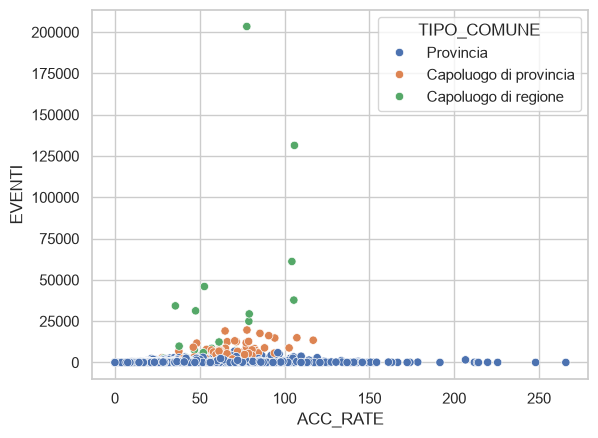

In [364]:
sns.scatterplot(data = incidenti_totale,x= 'ACC_RATE', y = 'EVENTI' , hue = 'TIPO_COMUNE' )


### Ho deciso di creare il dataframe 'incidenti_core' tenendo solo il 70% centrale dei comuni per eliminare eventuali outlier


In [365]:
# Creo il dataframe 'incidenti_core' tenendo solo il 70% centrale dei comuni

Q1 = incidenti_totale['EVENTI'].quantile(0.15)
Q3 = incidenti_totale['EVENTI'].quantile(0.85)

incidenti_core = incidenti_totale[(incidenti_totale['EVENTI'] >= Q1) & (incidenti_totale['EVENTI'] <= Q3)]
incidenti_core.describe()

,SUPERFICIE_KMQ,ALTITUDINE_m,EVENTI,FERITI,MORTI,POPOLAZIONE,ACC_RATE,ACC_KMQ
count,5408.000000,5408.000000,5408.000000,5408.000000,5408.000000,5408.000000,5408.000000,5408.000000
mean,33.169289,351.605769,81.304919,121.889793,3.168639,3425.234837,26.151385,5.816673
std,37.519830,281.758649,77.652663,116.615500,3.499008,2998.354464,19.934279,10.608724
min,0.120600,0.000000,7.000000,6.000000,0.000000,42.000000,2.199978,0.037551
25%,11.020075,129.000000,23.000000,33.000000,1.000000,1294.750000,14.080696,0.927715
50%,20.889150,290.500000,52.000000,79.000000,2.000000,2477.500000,21.927296,2.398430
75%,40.225425,500.000000,116.000000,174.000000,5.000000,4685.250000,32.321561,6.134432
max,372.506600,2035.000000,333.000000,662.000000,46.000000,34107.000000,265.822785,199.122290


### Con questo grafico possiamo osservare come la maggior parte dei comuni ha un `ACC_RATE` attorno a 20 incidenti / 1000 abitanti

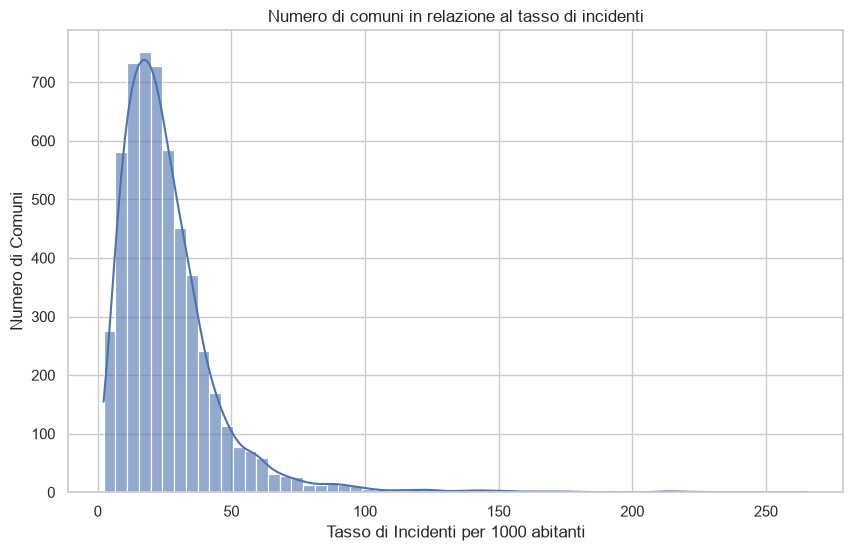

In [366]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(
    data=incidenti_core,
    x='ACC_RATE',
    bins=60,
    kde=True,
    stat='count',
    alpha=0.6
)

plt.title('Numero di comuni in relazione al tasso di incidenti')
plt.xlabel('Tasso di Incidenti per 1000 abitanti')
plt.ylabel('Numero di Comuni')
plt.show()

### Con questo grafico abbiamo invece la possibilità di vedere la classifica delle regioni con più incidenti

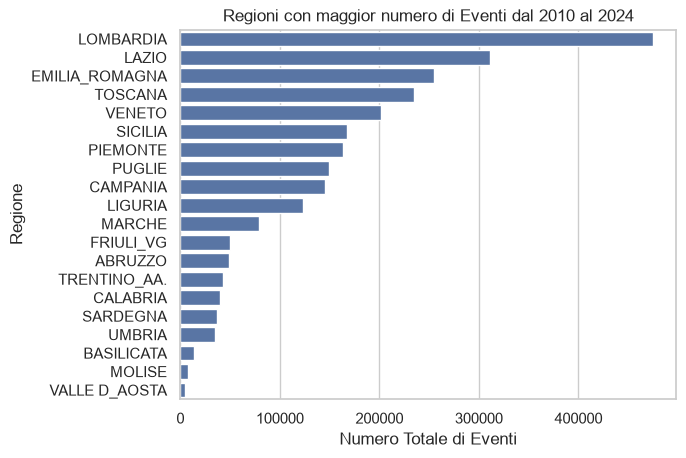

In [367]:
dati_regioni = (incidenti_totale.groupby('CODICE_REGIONE')['EVENTI'].sum().reset_index())
dati_regioni = dati_regioni.sort_values(by='EVENTI', ascending=False)
sns.barplot(
    data=dati_regioni,
    x='EVENTI',
    y='CODICE_REGIONE',
)
plt.title('Regioni con maggior numero di Eventi dal 2010 al 2024')
plt.xlabel('Numero Totale di Eventi')
plt.ylabel('Regione')
plt.show()

### Da qui 

In [368]:
incidenti_popolazione = incidenti_agg.loc[incidenti_agg['ANNO'] == 2024]
popolazione_2024 = incidenti_popolazione['POPOLAZIONE'].sum()
incidenti_popolazione_2010 = incidenti_agg.loc[incidenti_agg['ANNO'] == 2010]
popolazione_2010 = incidenti_popolazione_2010['POPOLAZIONE'].sum()


top_tasso = incidenti_totale.sort_values(by='ACC_RATE', ascending=False).head(1)
top_tasso_comune = top_tasso['NOME_COMUNE'].iloc[0]
top_tasso_valore = top_tasso['ACC_RATE'].iloc[0]

top_densità = incidenti_totale.sort_values(by='ACC_KMQ', ascending=False).head(1)
top_densità_comune = top_densità['NOME_COMUNE'].iloc[0]
top_acc_KMQ_rate = top_densità['ACC_KMQ'].iloc[0]

popolazione_media = incidenti_totale['POPOLAZIONE'].sum()
TOTALE_EVENTI = incidenti_totale['EVENTI'].sum()

print(f'Il comune con il tasso di incidenti per 1000 abitanti più alto è: {top_tasso_comune} con RATEO = {top_tasso_valore}')
print(f'Il comune con il tasso di incidenti per kmq più alto è: {top_densità_comune} con RATEO = {top_acc_KMQ_rate}')
print(f'Il totale degli incidenti avvenuti dal 2010 al 2024 è di: {TOTALE_EVENTI:d} eventi')
print(f'La popolazione nel 2010 è di: {int(popolazione_2010):d} individui')
print(f'La popolazione nel 2024 è di: {int(popolazione_2024):d} individui')
print(f'La popolazione media dal 2010 al 2024 è di: {int(popolazione_media):d} individui')

Il comune con il tasso di incidenti per 1000 abitanti più alto è: Argentera con RATEO = 265.82278481012656
Il comune con il tasso di incidenti per kmq più alto è: Milano con RATEO = 723.4713856292112
Il totale degli incidenti avvenuti dal 2010 al 2024 è di: 2582330 eventi
La popolazione nel 2010 è di: 58154103 individui
La popolazione nel 2024 è di: 56984400 individui
La popolazione media dal 2010 al 2024 è di: 58398209 individui


##### **Ipotesi nulla = il tasso di incidenti non cambia a seconda della zona altimetrica**
### Essendo il p-value = 5.57465314958633e-68, l'ipotesi nulla viene scartata: 
### questo dimostra che il tasso medio di incidenti varia in modo significativo tra le diverse zone altimetriche.

In [ ]:
pianura = incidenti_totale[incidenti_totale['ZONA_ALTIMETRICA'] == 'pianura']['ACC_RATE']
montagna_interna = incidenti_totale[incidenti_totale['ZONA_ALTIMETRICA'] == 'montagna interna']['ACC_RATE']
collina_interna = incidenti_totale[incidenti_totale['ZONA_ALTIMETRICA'] == 'collina interna']['ACC_RATE']
collina_litoranea = incidenti_totale[incidenti_totale['ZONA_ALTIMETRICA'] == 'collina litoranea']['ACC_RATE']
montagna_litoranea = incidenti_totale[incidenti_totale['ZONA_ALTIMETRICA'] == 'montagna litoranea']['ACC_RATE']

statistica_f, p_value = stats.f_oneway(pianura,montagna_interna,collina_interna,montagna_litoranea,collina_litoranea)

print(f'Statistica F: {statistica_f}')
print(f'P-value: {p_value}')

Statistica F: 81.65590865986562
P-value: 5.57465314958633e-68


### Con il metodo dei minimi quadrati possiamo osservare che la R2 è molto bassa (0,024) perciò la correlazione tra il tasso di incidenti e la popolazione è da considerare inesistente 

In [370]:
Y = incidenti_totale['ACC_RATE']
X = incidenti_totale['POPOLAZIONE']
X = sm.add_constant(data=X)
model = sm.OLS(endog=Y, exog=X)
results = model.fit()


print(results.summary())



                            OLS Regression Results                            
Dep. Variable:               ACC_RATE   R-squared:                       0.024
Model:                            OLS   Adj. R-squared:                  0.024
Method:                 Least Squares   F-statistic:                     188.8
Date:                Mon, 12 Oct 2026   Prob (F-statistic):           1.86e-42
Time:                        16:40:30   Log-Likelihood:                -34197.
No. Observations:                7646   AIC:                         6.840e+04
Df Residuals:                    7644   BIC:                         6.841e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const          25.7846      0.247    104.572      

### Possiamo osservare come montagna interna e pianura sono quasi allo stesso livello per ACC_RATE ma per ragioni completamente diverse 
#### nella  `Montagna interna` la maggior parte delle strade sono strette e tortuose con rischio di ghiaccio sull'asfalto o altri problemi causati dagli eventi atmosferici e naturali
#### mentre in `Pianura` essendo che c'è una quantità maggiore di strade ad alto traffico come tangenziali e autostrade fa aumentare il numero di incidenti per 1000 abitanti

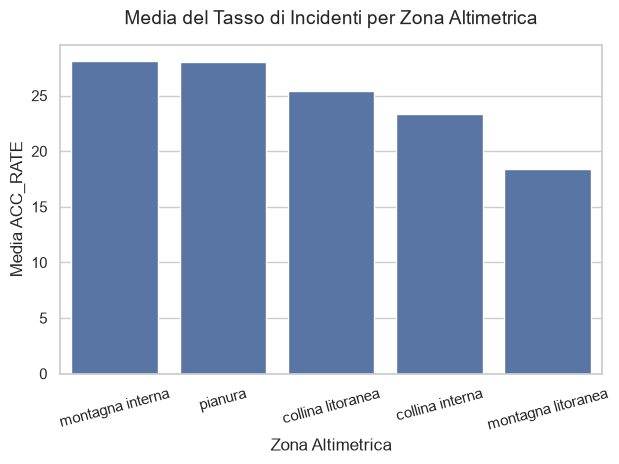

In [371]:
import matplotlib.pyplot as plt
import seaborn as sns

medie_zone = (incidenti_core.groupby('ZONA_ALTIMETRICA')['ACC_RATE'].mean().reset_index().sort_values(by='ACC_RATE', ascending=False))
sns.barplot(data=medie_zone,x='ZONA_ALTIMETRICA',y='ACC_RATE',order=medie_zone['ZONA_ALTIMETRICA'])

plt.title('Media del Tasso di Incidenti per Zona Altimetrica', fontsize=14, pad=15)
plt.xlabel('Zona Altimetrica')
plt.ylabel('Media ACC_RATE')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [376]:
incidenti_agg.to_csv("incidenti_agg")
incidenti_core.to_csv("incidenti_core")
incidenti_totale.to_csv("incidenti_totale")